# A/B Test Analysis: Balancing Scam Warning Prompts vs. Checkout Friction

### 1. Business Context & Problem Statement
Authorized Push Payment (APP) fraud is a major financial liability for digital banks and instant-transfer platforms. When customers are tricked into authorizing fraudulent transfers, banks face direct reimbursement costs and reputational damage. 

To combat this, the product team proposed adding a behavioral warning screen (*"Stop: Could this transfer be a scam?"*) before high-risk instant transfers. However, introducing extra checkout friction risks frustrating legitimate customers and causing them to abandon valid transfers—directly reducing transaction fee revenue.

### 2. Experiment Design & Dataset
* **Source Data:** Extracted and joined via SQL from three production logging tables (`experiment_assignments`, `transfer_events`, and `fraud_reports`), yielding **20,000 user transfer records**.
* **Traffic Split:** 50/50 randomized split between:
  * **Control (`n = 10,012`):** Standard instant-transfer flow (no warning prompt).
  * **Treatment (`n = 9,988`):** Transfer flow with the behavioral scam warning screen.
* **Methodology Note:** In a live production lifecycle, this analysis begins prior to test launch with a **pre-test power analysis** on historical baseline logs to establish the required sample size and test duration. This notebook picks up at the post-experiment evaluation stage once the target sample has been collected.

### 3. Evaluation Framework
To make a data-driven launch recommendation, this analysis evaluates two competing metrics using two-proportion $z$-tests ($\alpha = 0.05$) followed by a unit-economics ROI assessment:
1. **Primary Success Metric (Fraud Prevention):** Does the warning screen significantly reduce the rate of completed scam transfers?
2. **Guardrail Metric (Checkout Friction):** Does the warning screen significantly increase the abandonment rate among legitimate users?
3. **Business ROI:** Does the dollar value of prevented fraud outweigh the transaction fee revenue (1.5%) lost from abandoned legitimate transfers?

In [22]:
# importing libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats

In [23]:
# loading a/b experiment result to pandas

transaction = pd.read_csv('../data/processed-transaction-dataset-from-db.csv')

transaction.sample(10)

,user_id,group_name,transfer_id,amount,status,is_scam
17534,U_17535,Treatment,T_17535,121.53,completed,0
17627,U_17628,Treatment,T_17628,1495.45,completed,0
10823,U_10824,Control,T_10824,842.55,completed,0
19806,U_19807,Treatment,T_19807,791.47,completed,0
7992,U_07993,Control,T_07993,304.24,completed,0
5410,U_05411,Treatment,T_05411,1353.45,abandoned,0
19747,U_19748,Treatment,T_19748,365.53,completed,0
18301,U_18302,Control,T_18302,478.94,completed,0
19169,U_19170,Treatment,T_19170,1444.83,completed,0
4270,U_04271,Treatment,T_04271,630.18,completed,0


#### Exploratory Data Analysis (EDA)

In [24]:
transaction['status'].value_counts()

status
completed    19312
abandoned      688
Name: count, dtype: int64

In [25]:
transaction.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   user_id      20000 non-null  str    
 1   group_name   20000 non-null  str    
 2   transfer_id  20000 non-null  str    
 3   amount       20000 non-null  float64
 4   status       20000 non-null  str    
 5   is_scam      20000 non-null  int64  
dtypes: float64(1), int64(1), str(4)
memory usage: 937.6 KB


In [26]:
# Investigting statistics structure of data

transaction.describe()

,amount,is_scam
count,20000.000000,20000.000000
mean,775.006086,0.034250
std,418.793304,0.181875
min,50.010000,0.000000
25%,413.945000,0.000000
50%,774.975000,0.000000
75%,1140.627500,0.000000
max,1499.960000,1.000000


In [27]:
transaction.duplicated().any()

np.False_

Text(0.5, 0, 'Group Name')

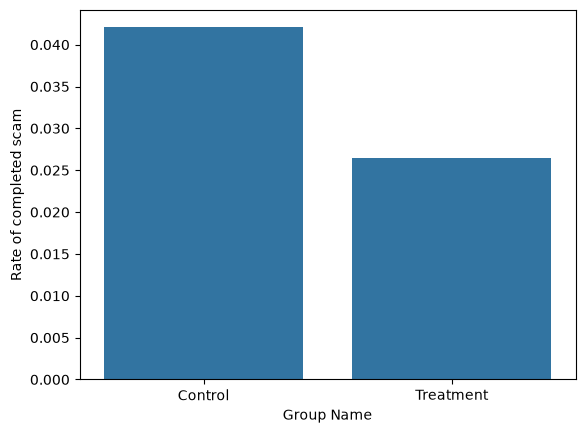

In [28]:
sns.barplot(transaction, x= 'group_name', y=transaction['is_scam'], errorbar= ('ci', False))

plt.ylabel('Rate of completed scam')
plt.xlabel('Group Name')

#### Extracting experiment groups

In [29]:
# extracting control transactions

control = transaction[transaction['group_name'] == 'Control']

control


,user_id,group_name,transfer_id,amount,status,is_scam
0,U_00001,Control,T_00001,483.42,completed,0
4,U_00005,Control,T_00005,345.30,completed,0
5,U_00006,Control,T_00006,401.28,completed,0
6,U_00007,Control,T_00007,420.42,completed,0
10,U_00011,Control,T_00011,1365.58,completed,0
...,...,...,...,...,...,...
19993,U_19994,Control,T_19994,1457.18,completed,0
19996,U_19997,Control,T_19997,591.20,completed,0
19997,U_19998,Control,T_19998,491.78,completed,0
19998,U_19999,Control,T_19999,640.68,completed,0


In [30]:
control_size = len(control)

In [31]:
# calculating control scam rate (scam rate before warning)

control_scam = control[control['is_scam'] == 1]

control_scam_completed = control_scam[control_scam['status'] == 'completed']
control_scam_completed_sum = len(control_scam_completed)



control_scam_rate = control_scam_completed_sum / control_size 
control_scam_rate

# without the warning sign, 4.21% of transactions were completed scam.

0.042049540551338395

In [32]:
# Calculating the rate of legitimate transactions that were abandoned (rate before warning)

control_legitimate = control[control['is_scam'] == 0]


control_legitimate_abandoned = control_legitimate[control_legitimate['status'] == 'abandoned']
control_legitimate_abandoned_sum = len(control_legitimate_abandoned)


control_legitimate_rate = control_legitimate_abandoned_sum / control_size
control_legitimate_rate

# without the warning sign, 2.77% of legitimate transactions were abandoned.

0.02766679984019177

In [33]:
# Extracting treament transactions (after warning transactions)

treatment = transaction[transaction['group_name'] == 'Treatment']

treatment.sample(4)

,user_id,group_name,transfer_id,amount,status,is_scam
1205,U_01206,Treatment,T_01206,403.59,completed,0
14224,U_14225,Treatment,T_14225,164.58,completed,0
1944,U_01945,Treatment,T_01945,616.35,completed,0
1469,U_01470,Treatment,T_01470,909.47,completed,0


In [34]:
treatment_size = len(treatment)
treatment_size

9988

In [35]:
# calculating treatment scam rate (scam rate after adding the warning)

treatment_scam = treatment[treatment['is_scam'] == 1]


treatment_scam_completed = treatment_scam[treatment_scam['status'] == 'completed']
treatment_scam_completed_sum = len(treatment_scam_completed)


treatment_scam_rate = treatment_scam_completed_sum / treatment_size
treatment_scam_rate


# after the warning sign was added, 2.64% of transactions were completed scam

0.02643171806167401

In [36]:
# Calculating treatment legitimate transactions that were abandoned

treatment_legitimate = treatment[treatment['is_scam'] == 0]

treatment_legitimate_abandoned = treatment_legitimate[treatment_legitimate['status'] == 'abandoned']
treatment_legitimate_abandoned_sum = len(treatment_legitimate_abandoned)


treatment_legitimate_abandoned_rate = treatment_legitimate_abandoned_sum / treatment_size
treatment_legitimate_abandoned_rate

# After the warning sign was included, 4.12% legitimate transactios were abandoned

0.04114937925510613

Established metrics from the A/B test:
- Before warning sign
    - completed scam = 4.21%
    - abandoned legitimate = 2.77%

- After warining sign
    - completed scam = 2.64%
    - abandoned legitimate = 4.12%

---
Now statistical Analysis

### Hypothesis 1

##### Hypothesis testing to compare if there is a statistically significant reduction in the completed scam rate before and after the warning sign was added.

*null hypothesis*: There is no difference in completed scam rate between the control and treatment groups.

*alternative hypothesis*: The rate of completed scam is higher in control than in treatment group.

In [37]:
# hypothesis testing to compare if there is a statistically significant reduction in the completed scam rate before and after the warning sign was added.

count = [control_scam_completed_sum, treatment_scam_completed_sum]
nob = [control_size, treatment_size]

zstats, pvalue = sm.stats.proportions_ztest(count, nob, alternative= 'larger')

print(zstats)
print(pvalue)

6.072150477619127
6.310429097478957e-10


In [38]:
# Calculating the difference between the scam rates in the control group(before warning) and the treatment group(after warning)

difference = control_scam_rate - treatment_scam_rate
difference

0.015617822489664385

In [39]:
# Calculating the unpooled proportional standard error 

se = np.sqrt(control_scam_rate * (1 - control_scam_rate) / control_size + treatment_scam_rate * (1 - treatment_scam_rate) / treatment_size )
se

np.float64(0.002568989998332843)

In [40]:
# Calculating the confidence interval of our estimated difference

lower_ci, upper_ci = stats.norm.interval(0.95, difference, se)

print(f'95% confidence interval: lower, upper ({lower_ci}, {upper_ci})')

95% confidence interval: lower, upper (0.010582694616288399, 0.020652950363040372)


#### hypothesis 1 Statistical Results

- P-value < 0.001. this is < 0.05

- z-stat = 6.07- z-stat = 6.07

- difference = 1.56 point

- 95% CI = (1.05 - 2.06)
    A pvalue lower than our significant level (0.05), we reject our null hypothesis. A pvalue higher than our significance level, we fail to reject the null hypothesis.Therefore we conclude with the alternative hypothesis. A positive zstat means the first group rate is the dominant rate.

    Meaning: We have statisically significant evidence that the rate of scam in the control group is higher than the treatment group witha difference of 1.56 point difference, witha 95%CI(1.05 - 2.06)

---
### Hypothesis 2

##### Hypothesis testing to compare if there is a statistically significant difference in the legitimate transaction abandonment rate before and after the warning sign was added.

*null hypothesis*: scam warning sign does not increase legitimate transaction abandonement.

*alternative hypothesis*: scam warning sign increases legitimate transaction abandonment.

In [41]:
# Hypothesis testing to compare if there is a statistically significant difference in the legitimate transaction abandonment rate before and after the warning sign was added.

counts = [ treatment_legitimate_abandoned_sum, control_legitimate_abandoned_sum]
nobs = [ treatment_size, control_size]

zstats, p_value = sm.stats.proportions_ztest(counts, nobs)

print(zstats)
print(p_value)

5.230941060936181
1.686492785367672e-07


In [42]:
# calculating the difference in the rate of abandoned legitimate transactions between control and treatment groups

diff =  treatment_legitimate_abandoned_rate - control_legitimate_rate
diff

0.013482579414914361

In [43]:
# Calculating the unpooled proportions standard error of legitimate transactions abandoned

se_legit = np.sqrt(treatment_legitimate_abandoned_rate *  (1 - treatment_legitimate_abandoned_rate) / treatment_size / control_legitimate_rate * (1 - control_legitimate_rate) / control_size)

se_legit

np.float64(0.00011775667302397654)

In [44]:
# calculate a 95% confidence interval of our difference

l_ci, u_ci = stats.norm.interval(0.95, diff, se_legit)

print(f'95% Confidence interval of abandoned legitimate transactions: lower, Upper: {l_ci},{u_ci}')

95% Confidence interval of abandoned legitimate transactions: lower, Upper: 0.013251780576848109,0.013713378252980614


#### hypothesis 2 Statistical Results

- P-value < 0.001. this is < 0.05

- z-stat = 5.23

- difference = 1.34% 

- 95% CI = (1.32 - 1.37)
    a pvalue lower than our significant level (0.05), we reject our null hypothesis. If our pvalue higher than our significance level, we fail to reject the null hypothesis.Terefore we conclude with the alternative hypothesis. A positive zstat means the first group rate is higher.

    Meaning: We have statisically significant evidence that the rate of abandoned legitimate transactions in the treatment group is higher than the control group witha difference of 1.34% point difference, with a 95%CI(1.32 - 1.37)

#### Business connection

How does the implementation of the warning sign affect the business monetarily.

does it increase revenue or reduce it?

In [45]:
# fee percent for all transactions is 1.5%

t_fee = 0.015     # 1.5%

In [46]:
money_saved = control_scam_completed['amount'].sum() - treatment_scam_completed['amount'].sum()

money_lost = (treatment_legitimate_abandoned['amount']* t_fee).sum() - (control_legitimate_abandoned['amount']* t_fee).sum()

print(f'money saved: ${money_saved:.2f}')
print(f'money lost: ${money_lost:.2f}')

money saved: $108752.15
money lost: $1350.59


In [47]:

net_roi = money_saved - money_lost

print(f'Money Saved: ${money_saved:.2f}')
print(f'Money Lost: ${money_lost:.2f}')
print(f'Net Impact (ROI): ${net_roi:.2f}')

Money Saved: $108752.15
Money Lost: $1350.59
Net Impact (ROI): $107401.57
